In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn
df = pd.read_excel(r"/content/BlinkIT Grocery Data (2).xlsx")

# Data Quality checking & cleaning


In [2]:
print("missing values \n",df.isnull().sum())
print(df.shape)

missing values 
 Item Fat Content                0
Item Identifier                 0
Item Type                       0
Outlet Establishment Year       0
Outlet Identifier               0
Outlet Location Type            0
Outlet Size                     0
Outlet Type                     0
Item Visibility                 0
Item Weight                  1463
Sales                           0
Rating                          0
dtype: int64
(8523, 12)


# Data Type cecking

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   object 
 1   Item Identifier            8523 non-null   object 
 2   Item Type                  8523 non-null   object 
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   object 
 5   Outlet Location Type       8523 non-null   object 
 6   Outlet Size                8523 non-null   object 
 7   Outlet Type                8523 non-null   object 
 8   Item Visibility            8523 non-null   float64
 9   Item Weight                7060 non-null   float64
 10  Sales                      8523 non-null   float64
 11  Rating                     8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


In [4]:
# Checking duplicates
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [5]:
# replacing the median value over averahe value because avg affected by outliers
median = df["Item Weight"].median()
df["Item Weight"].fillna(median, inplace=True)

/tmp/ipykernel_940/3694696209.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["Item Weight"].fillna(median, inplace=True)


In [6]:
# capitalizing each column with removing unusual spaces in eah column name
df.columns = df.columns.str.strip().str.capitalize()

In [7]:
# finding the duplicates categories to replace unique categories
df["Item fat content"].value_counts()

,count
Item fat content,
Low Fat,5089
Regular,2889
LF,316
reg,117
low fat,112


In [8]:
# replacing the duplicate categories with unique
fat_map = {
    "LF": "Low Fat",
    "low fat": "Low Fat",
    "Low Fat": "Low Fat",
    "reg": "Regular",
    "Regular": "Regular"}

df["Item fat content"] = df["Item fat content"].replace(fat_map)


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item fat content           8523 non-null   object 
 1   Item identifier            8523 non-null   object 
 2   Item type                  8523 non-null   object 
 3   Outlet establishment year  8523 non-null   int64  
 4   Outlet identifier          8523 non-null   object 
 5   Outlet location type       8523 non-null   object 
 6   Outlet size                8523 non-null   object 
 7   Outlet type                8523 non-null   object 
 8   Item visibility            8523 non-null   float64
 9   Item weight                8523 non-null   float64
 10  Sales                      8523 non-null   float64
 11  Rating                     8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


In [10]:
# rounding
df["Item_Visibility_Pct"] = (df["Item visibility"] * 100).round().astype(int)
df["Item weight"] = (df["Item weight"] * 100).round().astype(int)
df["Rating"] = (df["Rating"] * 100).round().astype(int)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item fat content           8523 non-null   object 
 1   Item identifier            8523 non-null   object 
 2   Item type                  8523 non-null   object 
 3   Outlet establishment year  8523 non-null   int64  
 4   Outlet identifier          8523 non-null   object 
 5   Outlet location type       8523 non-null   object 
 6   Outlet size                8523 non-null   object 
 7   Outlet type                8523 non-null   object 
 8   Item visibility            8523 non-null   float64
 9   Item weight                8523 non-null   int64  
 10  Sales                      8523 non-null   float64
 11  Rating                     8523 non-null   int64  
 12  Item_Visibility_Pct        8523 non-null   int64  
dtypes: float64(2), int64(4), object(7)
memory usage:

In [12]:
df.shape

(8523, 13)

In [13]:
df.to_excel("BlinkIT_Cleaned_Dataset.xlsx", index=False)
df.to_csv("BlinkIT_Cleaned_Dataset.csv", index=False)
print("Saved cleaned files successfully:", df.shape)

Saved cleaned files successfully: (8523, 13)


In [14]:
df.to_excel(r"C:\Users\YourName\Downloads\BlinkIT_Cleaned_Dataset.xlsx", index=False)

# EDA

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. UNIVARIATE ANALYSIS (ONE COLUMN AT A TIME)
print("Numeric summary:")
num_cols = ["Outlet establishment year", "Item visibility", "Item weight", "Sales", "Rating", "Item_Visibility_Pct"]
print(df[num_cols].describe().round(2))

print("\nCategory counts:")
for col in ["Item fat content", "Item type", "Outlet location type", "Outlet size", "Outlet type"]:
    print("\n---", col, "---")
    print(df[col].value_counts())

#2. BIVARIATE ANALYSIS (COMPARING TWO COLUMNS, MAINLY WITH SALES) ---
print("\nSales by Item type:")
print(df.groupby("Item type")["Sales"].agg(["count", "sum", "mean"]).sort_values("sum", ascending=False).round(2))

print("\nSales by Outlet type:")
print(df.groupby("Outlet type")["Sales"].agg(["count", "sum", "mean"]).sort_values("sum", ascending=False).round(2))

print("\nSales by Outlet location type:")
print(df.groupby("Outlet location type")["Sales"].agg(["count", "sum", "mean"]).sort_values("sum", ascending=False).round(2))

print("\nCorrelation with Sales:")
corr_cols = ["Item visibility", "Item_Visibility_Pct", "Item weight", "Rating", "Outlet establishment year", "Sales"]
print(df[corr_cols].corr()["Sales"].round(4))


Numeric summary:
       Outlet establishment year  Item visibility  Item weight    Sales  \
count                    8523.00          8523.00      8523.00  8523.00   
mean                     2016.45             0.07      1281.36   140.99   
std                         3.19             0.05       422.71    62.28   
min                      2011.00             0.00       456.00    31.29   
25%                      2014.00             0.03       931.00    93.83   
50%                      2016.00             0.05      1260.00   143.01   
75%                      2018.00             0.09      1600.00   185.64   
max                      2022.00             0.33      2135.00   266.89   

        Rating  Item_Visibility_Pct  
count  8523.00              8523.00  
mean    396.59                 6.62  
std      60.57                 5.16  
min     100.00                 0.00  
25%     400.00                 3.00  
50%     400.00                 5.00  
75%     420.00                 9.00  
max

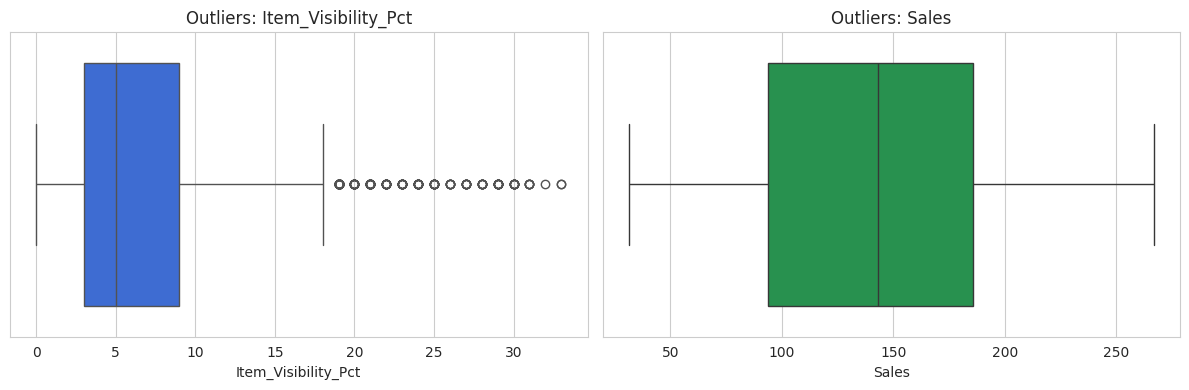

In [16]:
# outlier analysis
sn.set_style("whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sn.boxplot(x=df["Item_Visibility_Pct"], ax=axes[0], color="#2563EB")
axes[0].set_title("Outliers: Item_Visibility_Pct")
axes[0].set_xlabel("Item_Visibility_Pct")

sn.boxplot(x=df["Sales"], ax=axes[1], color="#16A34A")
axes[1].set_title("Outliers: Sales")
axes[1].set_xlabel("Sales")

plt.tight_layout()
plt.show()

# Item_Visibility_Pct shows a right-skewed distribution with high-visibility outliers extending above the upper whisker (above ~18 up to ~33), whereas Sales has no visible outliers outside its whiskers

/tmp/ipykernel_940/589158686.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sn.boxplot(data=df, x="Outlet type", y="Sales", ax=axes[1, 0], palette="Blues")
/tmp/ipykernel_940/589158686.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sn.barplot(data=df, x="Item fat content", y="Sales", estimator="sum", errorbar=None, ax=axes[1, 1], palette="Greens")


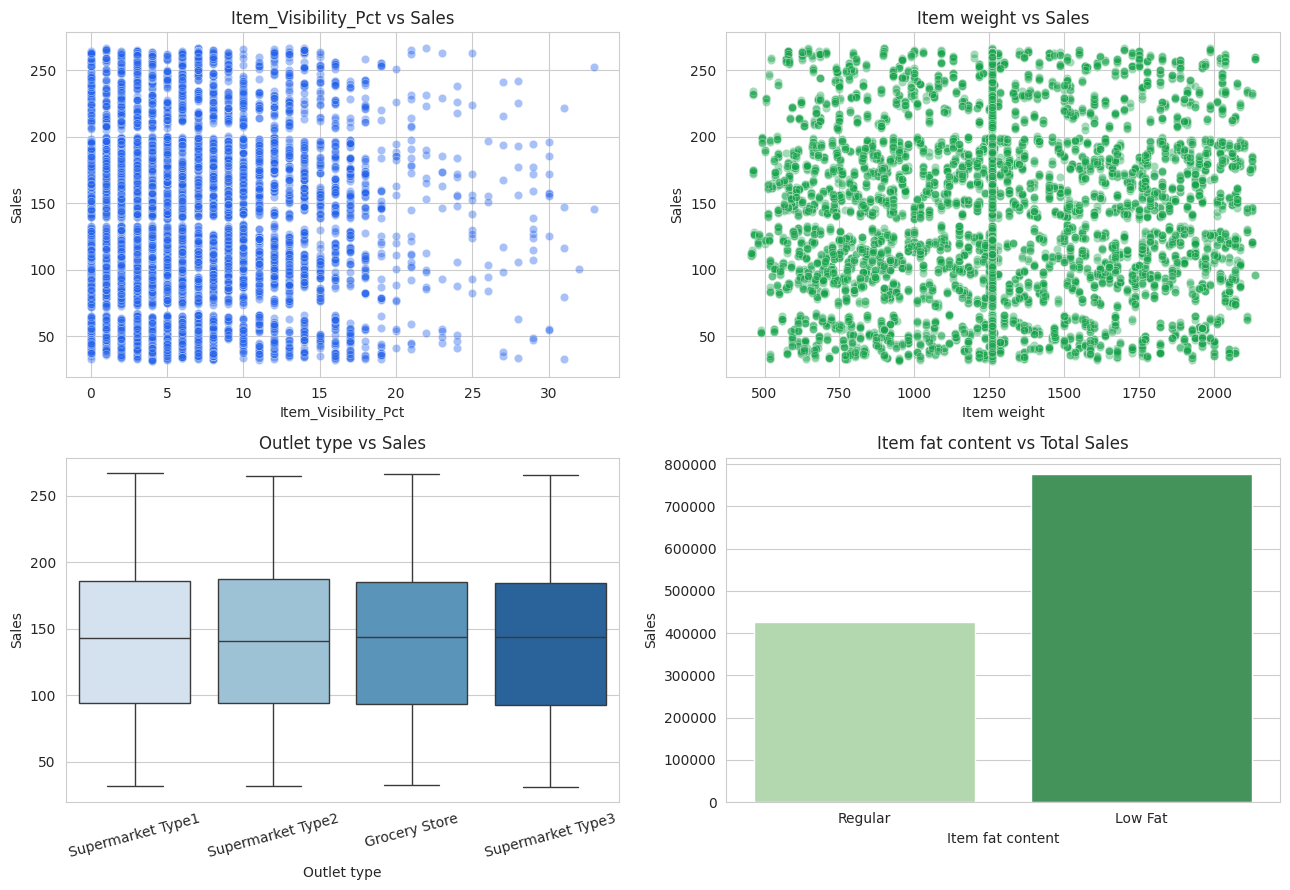

In [17]:
import matplotlib.pyplot as plt
import seaborn as sn

sn.set_style("whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Item_Visibility_Pct vs Sales
sn.scatterplot(data=df, x="Item_Visibility_Pct", y="Sales", ax=axes[0, 0], alpha=0.4, color="#2563EB")
axes[0, 0].set_title("Item_Visibility_Pct vs Sales")

# Item weight vs Sales
sn.scatterplot(data=df, x="Item weight", y="Sales", ax=axes[0, 1], alpha=0.4, color="#16A34A")
axes[0, 1].set_title("Item weight vs Sales")

# Outlet type vs Sales
sn.boxplot(data=df, x="Outlet type", y="Sales", ax=axes[1, 0], palette="Blues")
axes[1, 0].set_title("Outlet type vs Sales")
axes[1, 0].tick_params(axis="x", rotation=15)

# Item fat content vs Total Sales
sn.barplot(data=df, x="Item fat content", y="Sales", estimator="sum", errorbar=None, ax=axes[1, 1], palette="Greens")
axes[1, 1].set_title("Item fat content vs Total Sales")

plt.tight_layout()
plt.show()

# Bivariate Analysis Overview

##Item_Visibility_Pct vs. Sales: Sales values remain evenly spread across all visibility levels, indicating that higher visibility alone does not drive higher sales.   

##Item weight vs. Sales: Sales are uniformly distributed across item weights (with a visible vertical band around imputed weight values), showing no strong linear trend with weight.   

##Outlet type vs. Sales: Median sales and interquartile ranges stay consistent across Supermarket Type1, Supermarket Type2, Grocery Store, and Supermarket Type3, suggesting similar per-record sales distributions across store formats.   

##Item fat content vs. Total Sales: Low Fat items generate substantially higher cumulative sales than Regular items, reflecting a larger share of catalog volume.   

Tasks
Task 1.1: Understand what types of products BlinkIT is selling

Unique products (Item identifier): 1559
Unique categories (Item type): 16

Product listings by Item type:
                       Listings  Share (%)
Item type                                 
Fruits and Vegetables      1232      14.46
Snack Foods                1200      14.08
Household                   910      10.68
Frozen Foods                856      10.04
Dairy                       682       8.00
Canned                      649       7.61
Baking Goods                648       7.60
Health and Hygiene          520       6.10
Soft Drinks                 445       5.22
Meat                        425       4.99
Breads                      251       2.94
Hard Drinks                 214       2.51
Others                      169       1.98
Starchy Foods               148       1.74
Breakfast                   110       1.29
Seafood                      64       0.75

Product listings by Item fat content:
                  Listings  Share (%)
Item fat content                     
Low F

/tmp/ipykernel_940/4127675980.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sn.countplot(data=df, x="Item fat content", order=fat_counts.index, ax=axes[1], palette="Greens")


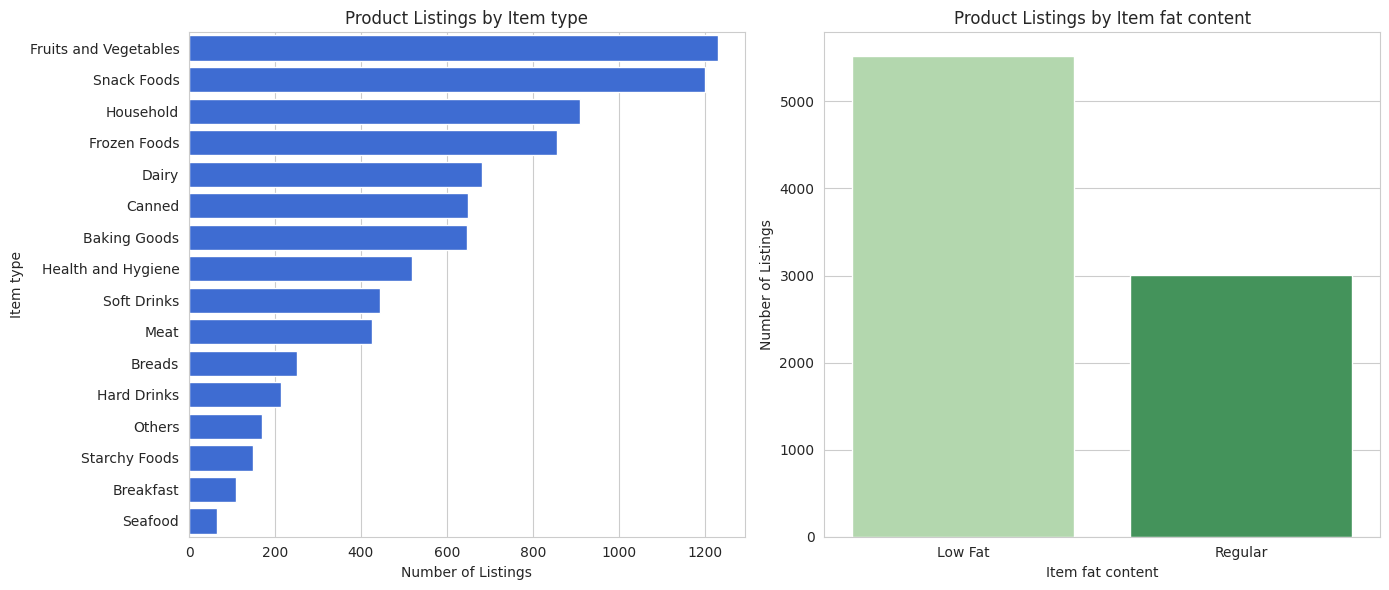

In [18]:
# Unique products and categories
print("Unique products (Item identifier):", df["Item identifier"].nunique())
print("Unique categories (Item type):", df["Item type"].nunique())

# Category breakdown
cat_counts = df["Item type"].value_counts()
cat_pct = (df["Item type"].value_counts(normalize=True) * 100).round(2)
print("\nProduct listings by Item type:")
print(pd.DataFrame({"Listings": cat_counts, "Share (%)": cat_pct}))

# Fat content breakdown
fat_counts = df["Item fat content"].value_counts()
fat_pct = (df["Item fat content"].value_counts(normalize=True) * 100).round(2)
print("\nProduct listings by Item fat content:")
print(pd.DataFrame({"Listings": fat_counts, "Share (%)": fat_pct}))

# Visual summary
sn.set_style("whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sn.countplot(data=df, y="Item type", order=cat_counts.index, ax=axes[0], color="#2563EB")
axes[0].set_title("Product Listings by Item type")
axes[0].set_xlabel("Number of Listings")
axes[0].set_ylabel("Item type")

sn.countplot(data=df, x="Item fat content", order=fat_counts.index, ax=axes[1], palette="Greens")
axes[1].set_title("Product Listings by Item fat content")
axes[1].set_xlabel("Item fat content")
axes[1].set_ylabel("Number of Listings")

plt.tight_layout()
plt.show()

# Task 1.2: Understand the Different Types and Locations of BlinkIT Outlets


Total outlets
10

Outlet types
Outlet type
Supermarket Type1    5577
Grocery Store        1083
Supermarket Type3     935
Supermarket Type2     928
Name: count, dtype: int64

Outlet sizes
Outlet size
Medium    3631
Small     3139
High      1753
Name: count, dtype: int64

Outlet locations
Outlet location type
Tier 3    3350
Tier 2    2785
Tier 1    2388
Name: count, dtype: int64

Outlet type vs Location
Outlet location type  Tier 1  Tier 2  Tier 3
Outlet type                                 
Grocery Store            528       0     555
Supermarket Type1       1860    2785     932
Supermarket Type2          0       0     928
Supermarket Type3          0       0     935

Outlet type vs Size
Outlet size        High  Medium  Small
Outlet type                           
Grocery Store       233     265    585
Supermarket Type1  1520    1503   2554
Supermarket Type2     0     928      0
Supermarket Type3     0     935      0

Outlet establishment year
Outlet establishment year
2018    1463
201

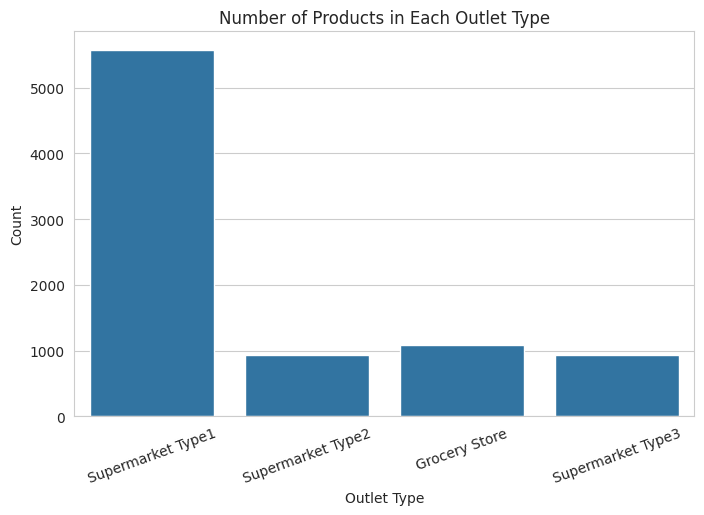

In [19]:
# 1. How many outlets are there?
print("\nTotal outlets")
print(df["Outlet identifier"].nunique())

# 2. What are the different Outlet types?
print("\nOutlet types")
print(df["Outlet type"].value_counts())

# 3. What are the different Outlet sizes?
print("\nOutlet sizes")
print(df["Outlet size"].value_counts())

# 4. What are the different Outlet locations?
print("\nOutlet locations")
print(df["Outlet location type"].value_counts())

# 5. Outlet type and Location together
print("\nOutlet type vs Location")
table1 = pd.crosstab(df["Outlet type"], df["Outlet location type"])
print(table1)

# 6. Outlet type and Size together
print("\nOutlet type vs Size")
table2 = pd.crosstab(df["Outlet type"], df["Outlet size"])
print(table2)

# 7. In which year outlets were started?
print("\nOutlet establishment year")
print(df["Outlet establishment year"].value_counts())

# 8. How many products in each Outlet?
print("\nProducts in each outlet")
print(df["Outlet identifier"].value_counts())

# How many products in each Outlet Type?
print("\nOutlet Type - Bar Graph")
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Outlet type")
plt.title("Number of Products in Each Outlet Type")
plt.xlabel("Outlet Type")
plt.ylabel("Count")
plt.xticks(rotation=20)
plt.show()

# Task 1.3: Understand how much BlinkIT is selling overall.

In [20]:
# 1. Total Sales of BlinkIT
print("\nTotal Sales")
print(df["Sales"].sum())

# 2. Average Sales per product
print("\nAverage Sales")
print(df["Sales"].mean())

# 3. Highest Sales and Lowest Sales
print("\nHighest Sales")
print(df["Sales"].max())
print("\nLowest Sales")
print(df["Sales"].min())

# 4. Total number of products sold
print("\nTotal products")
print(df["Sales"].count())

# 5. Sales summary - all in one
print("\nSales summary")
print(df["Sales"].describe())


Total Sales
1201681.4928000001

Average Sales
140.99278338613166

Highest Sales
266.8884

Lowest Sales
31.29

Total products
8523

Sales summary
count    8523.000000
mean      140.992783
std        62.275067
min        31.290000
25%        93.826500
50%       143.012800
75%       185.643700
max       266.888400
Name: Sales, dtype: float64


# Task 1.4: Understand the overall customer rating and product performance.


Average Rating
396.5857092573038

Highest Rating
500

Lowest Rating
100

Rating summary
count    8523.000000
mean      396.585709
std        60.565128
min       100.000000
25%       400.000000
50%       400.000000
75%       420.000000
max       500.000000
Name: Rating, dtype: float64

Rating by Item Type
Item type
Meat                     402.305882
Household                399.868132
Canned                   399.429892
Health and Hygiene       398.615385
Baking Goods             398.302469
Frozen Foods             397.114486
Dairy                    396.583578
Seafood                  395.937500
Fruits and Vegetables    395.616883
Others                   395.443787
Snack Foods              394.891667
Breakfast                393.272727
Soft Drinks              392.067416
Starchy Foods            392.027027
Hard Drinks              390.747664
Breads                   388.127490
Name: Rating, dtype: float64


/tmp/ipykernel_940/285295667.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sn.barplot(x=table1.index, y=table1.values, palette="viridis")


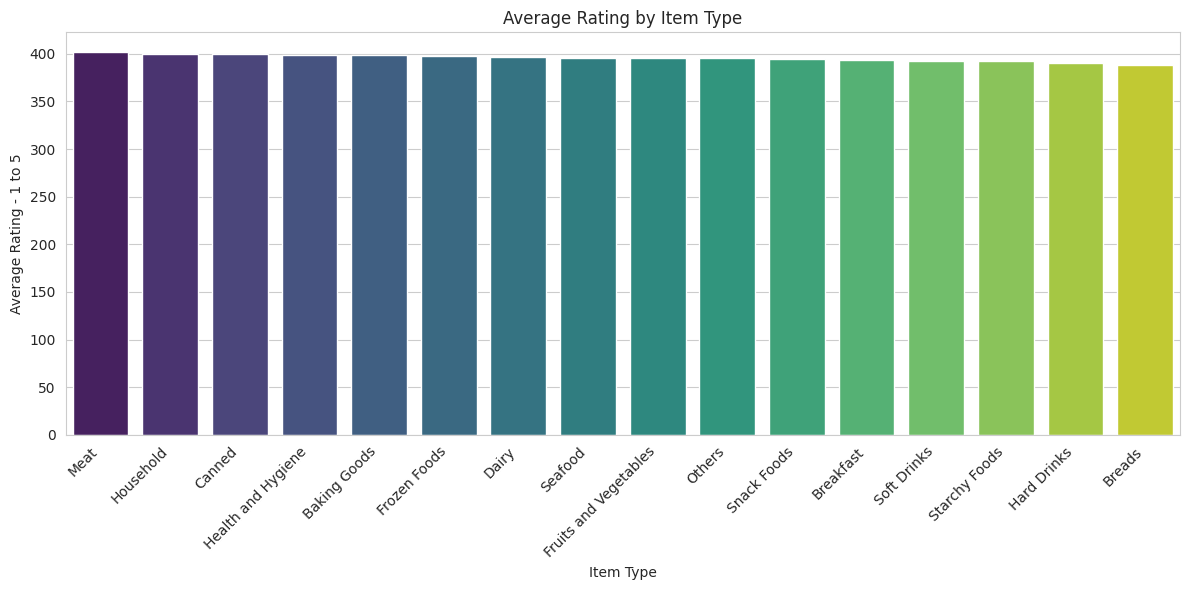


Sales by Item Type
Item type
Fruits and Vegetables    178124.0810
Snack Foods              175433.9224
Household                135976.5254
Frozen Foods             118558.8814
Dairy                    101276.4616
Canned                    90706.7290
Baking Goods              81894.7364
Health and Hygiene        68025.8388
Meat                      59449.8638
Soft Drinks               58514.1670
Breads                    35379.1198
Hard Drinks               29334.6806
Others                    22451.8916
Starchy Foods             21880.0274
Breakfast                 15596.6966
Seafood                    9077.8700
Name: Sales, dtype: float64


/tmp/ipykernel_940/285295667.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sn.barplot(x=table3.index, y=table3.values, palette="viridis")


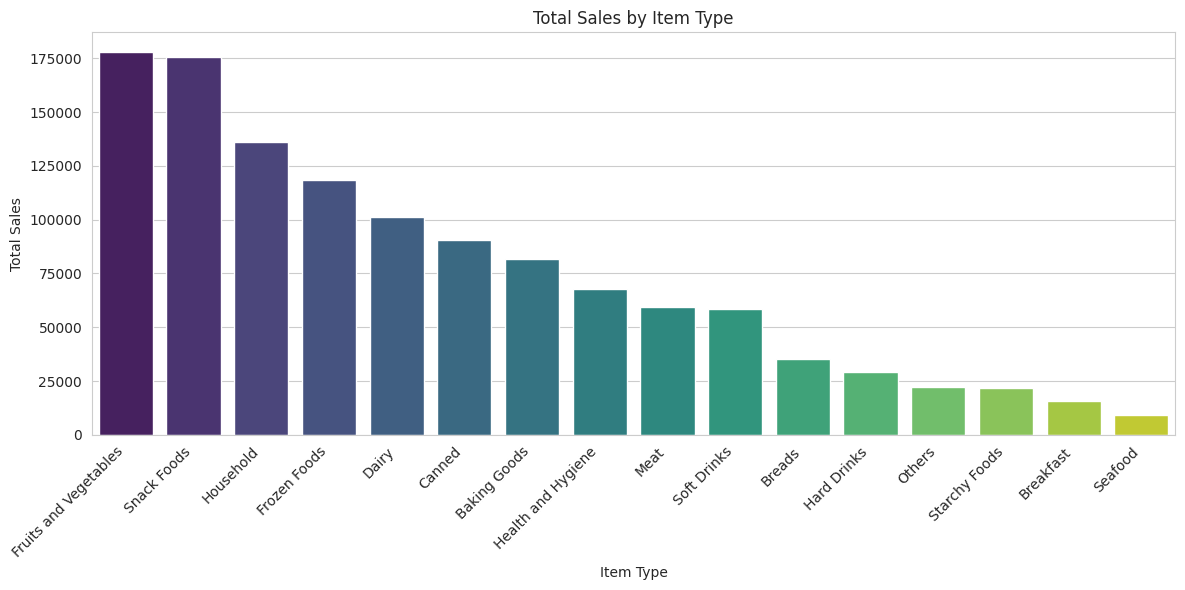


Rating vs Sales


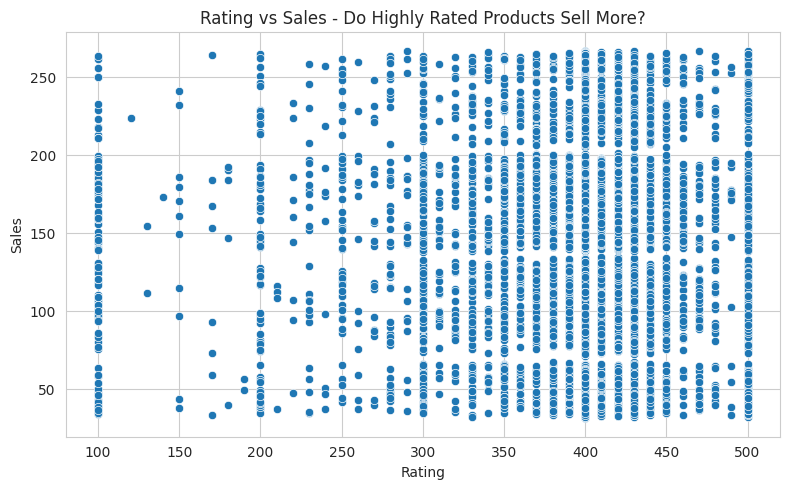

In [21]:
# Style for all graphs - only one time
sns.set_style("whitegrid")

# 1. Average Rating of all products
print("\nAverage Rating")
print(df["Rating"].mean())

# 2. Highest Rating and Lowest Rating
print("\nHighest Rating")
print(df["Rating"].max())
print("\nLowest Rating")
print(df["Rating"].min())

# 3. Rating summary
print("\nRating summary")
print(df["Rating"].describe())

# Style for all graphs
sn.set_style("whitegrid")

 # 5. Which Item Type has Highest Rating?
print("\nRating by Item Type")
table1 = df.groupby("Item type")["Rating"].mean()
table1 = table1.sort_values(ascending=False)
print(table1)
plt.figure(figsize=(12, 6))
sn.barplot(x=table1.index, y=table1.values, palette="viridis")
plt.title("Average Rating by Item Type")
plt.xlabel("Item Type")
plt.ylabel("Average Rating - 1 to 5")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# 6. Which Item Type has Highest Sales?
print("\nSales by Item Type")
table3 = df.groupby("Item type")["Sales"].sum()
table3 = table3.sort_values(ascending=False)
print(table3)
plt.figure(figsize=(12, 6))
sn.barplot(x=table3.index, y=table3.values, palette="viridis")
plt.title("Total Sales by Item Type")
plt.xlabel("Item Type")
plt.ylabel("Total Sales")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# 7. Does High Rating mean High Sales?
print("\nRating vs Sales")
plt.figure(figsize=(8, 5))
sn.scatterplot(data=df, x="Rating", y="Sales")
plt.title("Rating vs Sales - Do Highly Rated Products Sell More?")
plt.xlabel("Rating")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

In [22]:
df.columns

Index(['Item fat content', 'Item identifier', 'Item type',
       'Outlet establishment year', 'Outlet identifier',
       'Outlet location type', 'Outlet size', 'Outlet type', 'Item visibility',
       'Item weight', 'Sales', 'Rating', 'Item_Visibility_Pct'],
      dtype='object')

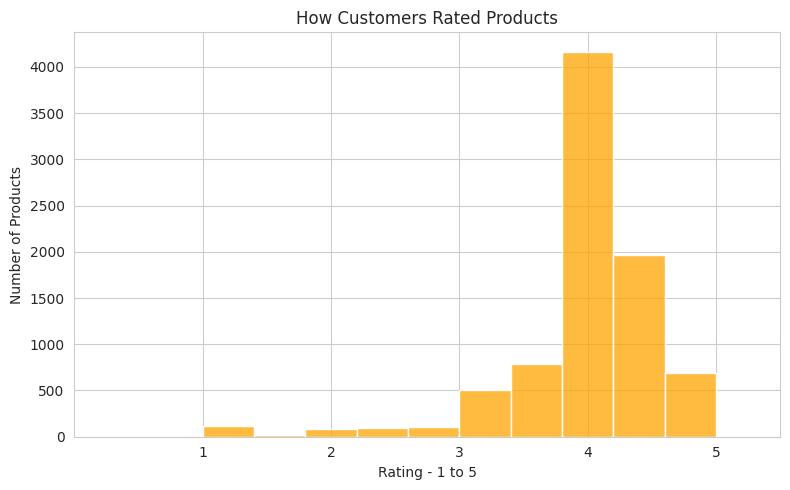

In [23]:
# 4. How are Ratings distributed?
while df["Rating"].max() < 1:
    df["Rating"] = df["Rating"] * 100
while df["Rating"].max() > 5:
    df["Rating"] = df["Rating"] / 100
plt.figure(figsize=(8, 5))
sn.histplot(data=df, x="Rating", bins=10, color="orange")
plt.title("How Customers Rated Products")
plt.xlabel("Rating - 1 to 5")
plt.ylabel("Number of Products")
plt.xlim(0, 5.5)
plt.xticks([1, 2, 3, 4, 5])
plt.tight_layout()
plt.show()

Total in Spike: 5091 out of 8523
Spike %: 59.7 %

--- By Outlet Location Type ---
Outlet location type
Tier 3    1985
Tier 2    1667
Tier 1    1439
Name: count, dtype: int64
Outlet location type
Tier 3    39.0
Tier 2    32.7
Tier 1    28.3
Name: proportion, dtype: float64

--- Spike Rate by Region ---
Outlet location type
Tier 1    60.3
Tier 2    59.9
Tier 3    59.3
Name: Rating, dtype: float64

--- By Outlet Type ---
Outlet type
Supermarket Type1    3312
Grocery Store         652
Supermarket Type3     572
Supermarket Type2     555
Name: count, dtype: int64

--- By Outlet Size ---
Outlet size
Medium    2166
Small     1906
High      1019
Name: count, dtype: int64

--- By Item Type in Spike ---
Item type
Fruits and Vegetables    735
Snack Foods              696
Household                543
Frozen Foods             514
Dairy                    415
Baking Goods             407
Canned                   398
Health and Hygiene       306
Meat                     260
Soft Drinks              25

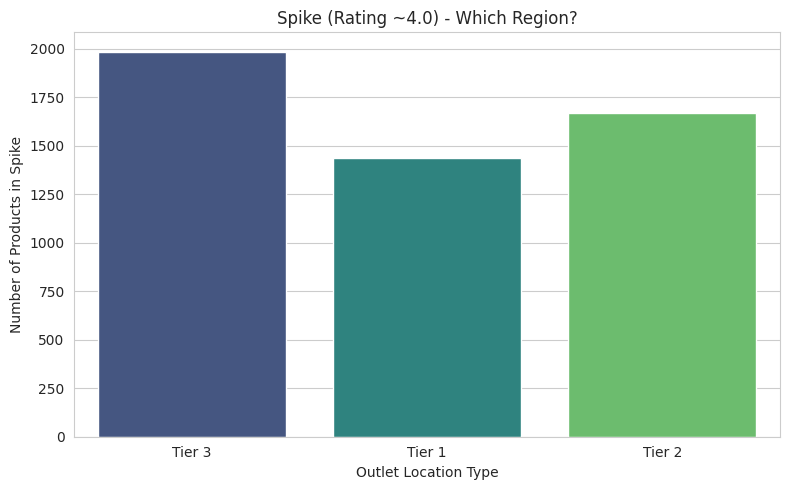

In [24]:
# Investigate Spike at Rating ~4.0
spike = df[(df["Rating"] >= 3.75) & (df["Rating"] < 4.25)]
print("Total in Spike:", len(spike), "out of", len(df))
print("Spike %:", round(len(spike)/len(df)*100, 1), "%")

# Which Region / Outlet Location drives spike?
print("\n--- By Outlet Location Type ---")
print(spike["Outlet location type"].value_counts())
print(spike["Outlet location type"].value_counts(normalize=True).round(3)*100)

print("\n--- Spike Rate by Region ---")
print(df.groupby("Outlet location type")["Rating"].apply(lambda x: ((x>=3.75)&(x<4.25)).mean().round(3)*100))

print("\n--- By Outlet Type ---")
print(spike["Outlet type"].value_counts())

print("\n--- By Outlet Size ---")
print(spike["Outlet size"].value_counts())

print("\n--- By Item Type in Spike ---")
print(spike["Item type"].value_counts().head(10))

# Visual - Spike by Region
plt.figure(figsize=(8, 5))
sn.countplot(data=spike, x="Outlet location type", hue="Outlet location type", palette="viridis", legend=False)
plt.title("Spike (Rating ~4.0) - Which Region?")
plt.xlabel("Outlet Location Type")
plt.ylabel("Number of Products in Spike")
plt.tight_layout()
plt.show()

# Find Out What Is Driving Better Sales Performance

Task 3.1: Find out which types of products are selling more


--- Sales by Item Type ---
                       Total_Sales  Avg_Sales  Count
Item type                                           
Fruits and Vegetables    178124.08     144.58   1232
Snack Foods              175433.92     146.19   1200
Household                135976.53     149.42    910
Frozen Foods             118558.88     138.50    856
Dairy                    101276.46     148.50    682
Canned                    90706.73     139.76    649
Baking Goods              81894.74     126.38    648
Health and Hygiene        68025.84     130.82    520
Meat                      59449.86     139.88    425
Soft Drinks               58514.17     131.49    445
Breads                    35379.12     140.95    251
Hard Drinks               29334.68     137.08    214
Others                    22451.89     132.85    169
Starchy Foods             21880.03     147.84    148
Breakfast                 15596.70     141.79    110
Seafood                    9077.87     141.84     64


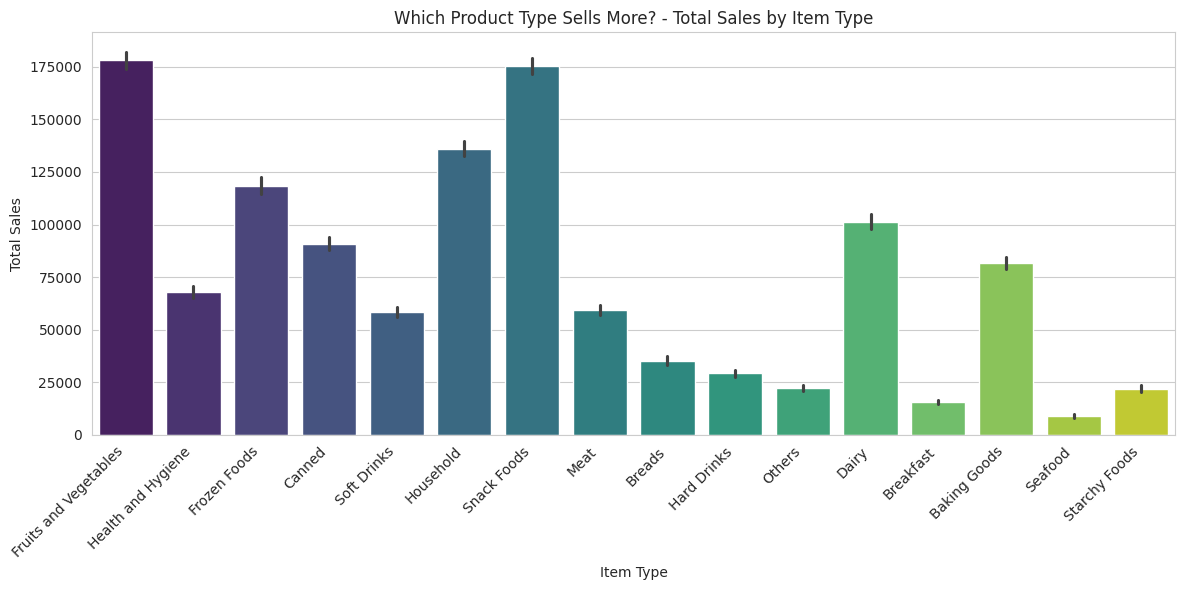


--- Sales by Item Fat Content ---
                        sum    mean  count
Item fat content                          
Low Fat           776319.69  140.71   5517
Regular           425361.80  141.50   3006


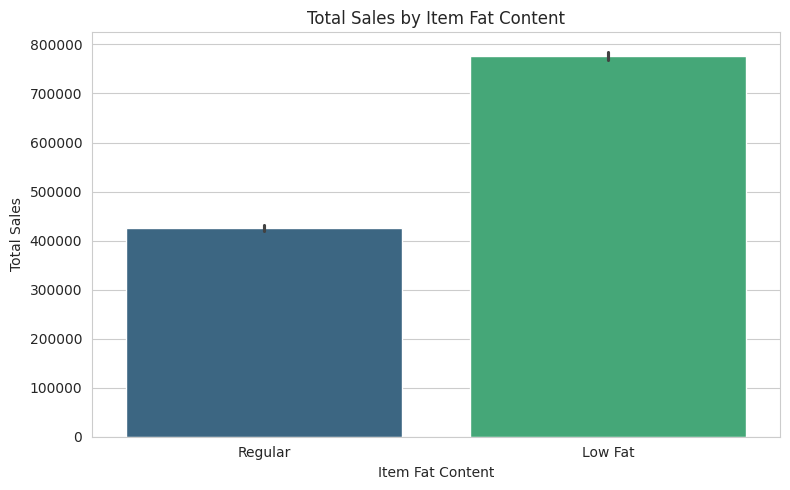


--- Top 10 Best Selling Products ---
Item identifier
FDU12    2371.01
FDT07    2306.90
NCQ06    2294.71
FDL58    2111.65
NCB31    2104.73
FDX31    2104.46
FDF05    2103.13
FDR59    2096.58
FDP28    2087.85
FDA04    2072.07
Name: Sales, dtype: float64


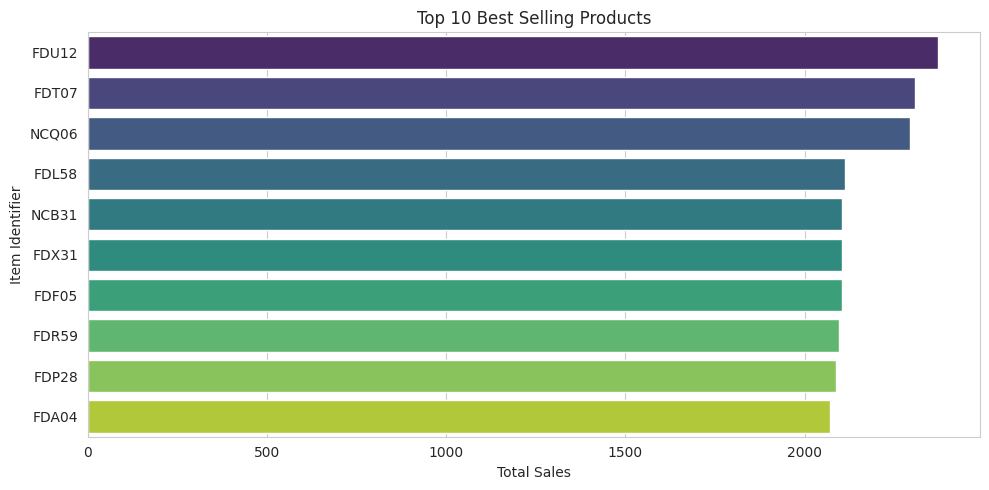

In [25]:
# Task 3.1: Which types of products are selling more?

# 3.1a By Item Type - Total Sales
print("\n--- Sales by Item Type ---")
t1 = df.groupby("Item type")["Sales"].agg(["sum", "mean", "count"]).sort_values("sum", ascending=False)
t1.columns = ["Total_Sales", "Avg_Sales", "Count"]
print(t1.round(2))

plt.figure(figsize=(12, 6))
sn.barplot(data=df, x="Item type", y="Sales", estimator="sum", hue="Item type", palette="viridis", legend=False)
plt.title("Which Product Type Sells More? - Total Sales by Item Type")
plt.xlabel("Item Type")
plt.ylabel("Total Sales")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# 3.1b By Item Fat Content
print("\n--- Sales by Item Fat Content ---")
t2 = df.groupby("Item fat content")["Sales"].agg(["sum", "mean", "count"]).sort_values("sum", ascending=False)
print(t2.round(2))

plt.figure(figsize=(8, 5))
sn.barplot(data=df, x="Item fat content", y="Sales", estimator="sum", hue="Item fat content", palette="viridis", legend=False)
plt.title("Total Sales by Item Fat Content")
plt.xlabel("Item Fat Content")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

# 3.1c Top 10 Individual Products
print("\n--- Top 10 Best Selling Products ---")
t3 = df.groupby("Item identifier")["Sales"].sum().sort_values(ascending=False).head(10)
print(t3.round(2))

plt.figure(figsize=(10, 5))
sn.barplot(x=t3.values, y=t3.index, hue=t3.index, palette="viridis", legend=False)
plt.title("Top 10 Best Selling Products")
plt.xlabel("Total Sales")
plt.ylabel("Item Identifier")
plt.tight_layout()
plt.show()

# Task 3.2: Find out which types of outlets are performing better.

['Item Fat Content', 'Item Identifier', 'Item Type', 'Outlet Establishment Year', 'Outlet Identifier', 'Outlet Location Type', 'Outlet Size', 'Outlet Type', 'Item Visibility', 'Item Weight', 'Sales', 'Rating', 'Item_Visibility_Pct']

--- Sales by Outlet Type ---
                   Total_Sales  Avg_Sales  Count
Outlet Type                                     
Supermarket Type1    787549.89     141.21   5577
Grocery Store        151939.15     140.29   1083
Supermarket Type2    131477.78     141.68    928
Supermarket Type3    130714.67     139.80    935


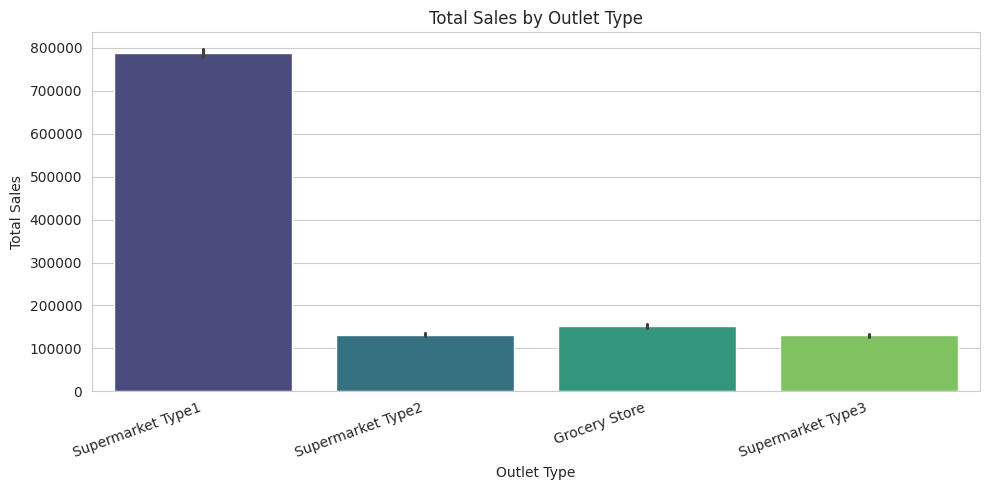


--- Sales by Outlet Size ---
                   sum    mean  count
Outlet Size                          
Medium       507895.74  139.88   3631
Small        444794.17  141.70   3139
High         248991.59  142.04   1753


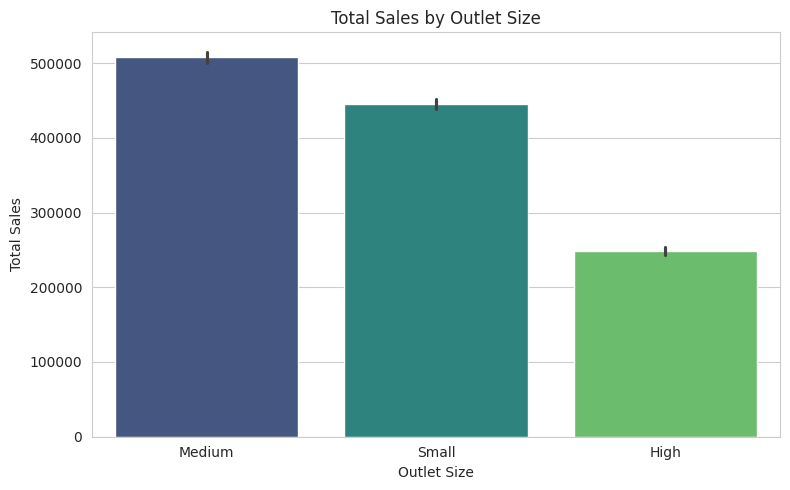


--- Sales by Outlet Location Type ---
                            sum    mean  count
Outlet Location Type                          
Tier 3                472133.03  140.94   3350
Tier 2                393150.65  141.17   2785
Tier 1                336397.81  140.87   2388


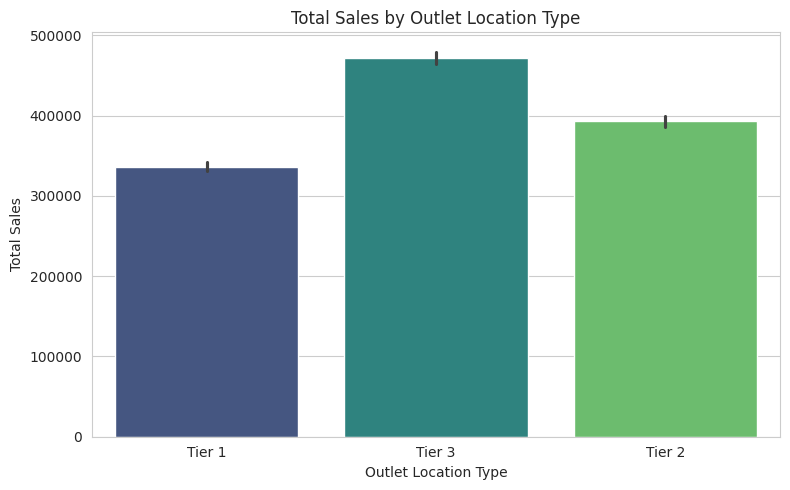


--- Sales by Outlet Type + Location ---
Outlet Type        Outlet Location Type
Supermarket Type1  Tier 2                  393150.65
                   Tier 1                  262590.23
                   Tier 3                  131809.02
Supermarket Type2  Tier 3                  131477.78
Supermarket Type3  Tier 3                  130714.67
Grocery Store      Tier 3                   78131.57
                   Tier 1                   73807.58
Name: Sales, dtype: float64


In [26]:
# Capitalize All Column Names
df.columns = df.columns.str.strip().str.title()
print(df.columns.tolist())

# Task 3.2: Which types of outlets are performing better?

# 3.2a By Outlet Type
print("\n--- Sales by Outlet Type ---")
o1 = df.groupby("Outlet Type")["Sales"].agg(["sum", "mean", "count"]).sort_values("sum", ascending=False)
o1.columns = ["Total_Sales", "Avg_Sales", "Count"]
print(o1.round(2))

plt.figure(figsize=(10, 5))
sn.barplot(data=df, x="Outlet Type", y="Sales", estimator="sum", hue="Outlet Type", palette="viridis", legend=False)
plt.title("Total Sales by Outlet Type")
plt.xlabel("Outlet Type")
plt.ylabel("Total Sales")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

# 3.2b By Outlet Size
print("\n--- Sales by Outlet Size ---")
o2 = df.groupby("Outlet Size")["Sales"].agg(["sum", "mean", "count"]).sort_values("sum", ascending=False)
print(o2.round(2))

plt.figure(figsize=(8, 5))
sn.barplot(data=df, x="Outlet Size", y="Sales", estimator="sum", hue="Outlet Size", palette="viridis", legend=False)
plt.title("Total Sales by Outlet Size")
plt.xlabel("Outlet Size")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

# 3.2c By Outlet Location Type
print("\n--- Sales by Outlet Location Type ---")
o3 = df.groupby("Outlet Location Type")["Sales"].agg(["sum", "mean", "count"]).sort_values("sum", ascending=False)
print(o3.round(2))

plt.figure(figsize=(8, 5))
sn.barplot(data=df, x="Outlet Location Type", y="Sales", estimator="sum", hue="Outlet Location Type", palette="viridis", legend=False)
plt.title("Total Sales by Outlet Location Type")
plt.xlabel("Outlet Location Type")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()



# 3.2d Outlet Type + Location Combined
print("\n--- Sales by Outlet Type + Location ---")
o5 = df.groupby(["Outlet Type", "Outlet Location Type"])["Sales"].sum().sort_values(ascending=False)
print(o5.round(2))

# Task 3.3: Understand whether product visibility, weight, ratings, and outlet characteristics are connected with sales.



--- Correlation With Sales ---
Sales                        1.000
Item Weight                  0.025
Rating                       0.011
Outlet Establishment Year   -0.001
Item Visibility             -0.001
Name: Sales, dtype: float64


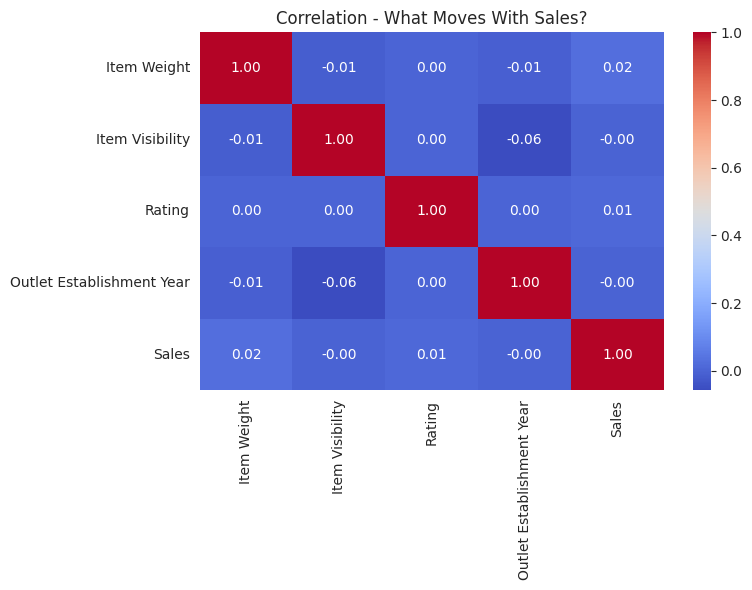

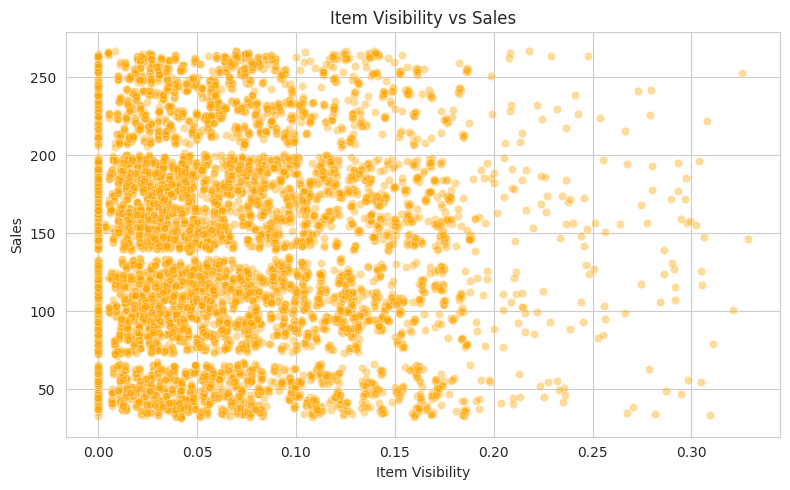

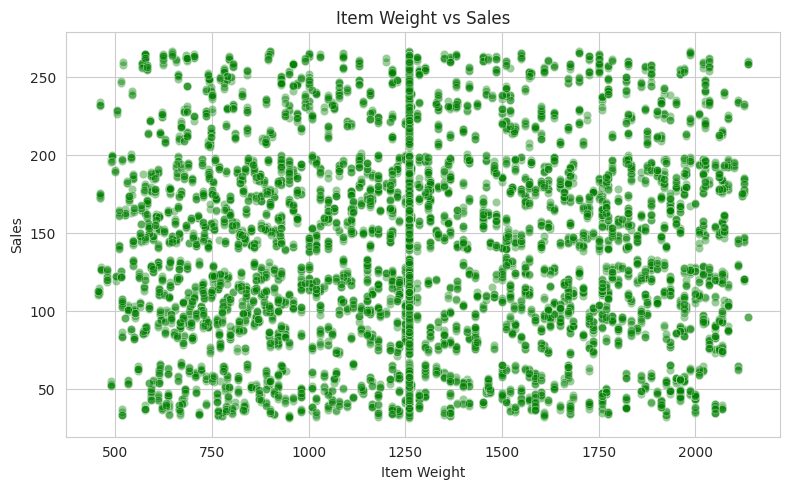

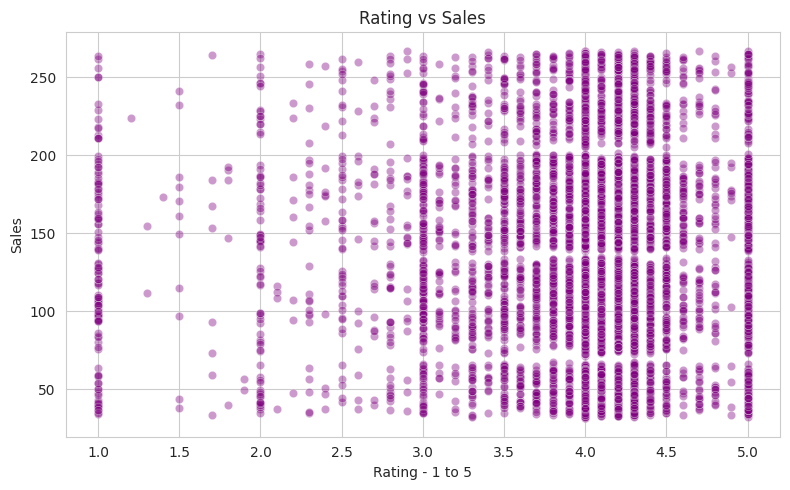


--- Correlation: Outlet Age vs Sales ---
            Outlet Age  Sales
Outlet Age       1.000  0.001
Sales            0.001  1.000


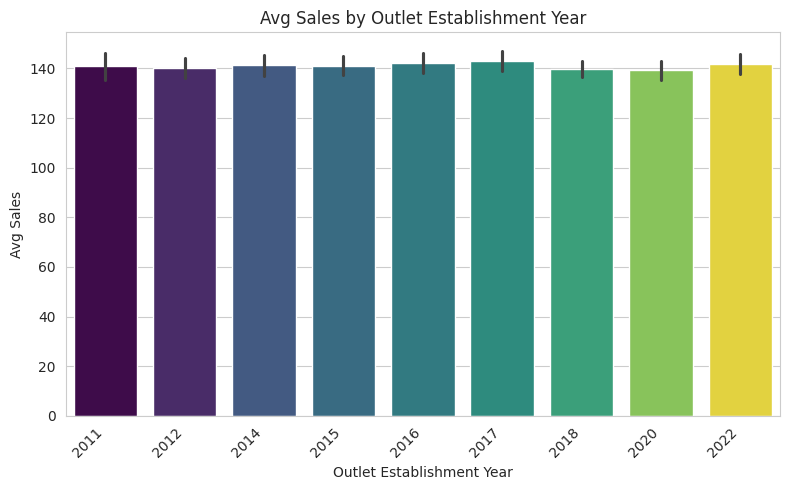

In [27]:
# Task 3.3: Are Visibility, Weight, Rating, Outlet Characteristics Connected With Sales?

# 3.3a Correlation Matrix - Numeric Columns
print("\n--- Correlation With Sales ---")
num = df[["Item Weight", "Item Visibility", "Rating", "Outlet Establishment Year", "Sales"]]
print(num.corr()["Sales"].sort_values(ascending=False).round(3))

plt.figure(figsize=(8, 6))
sn.heatmap(num.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation - What Moves With Sales?")
plt.tight_layout()
plt.show()

# 3.3b Visibility vs Sales
plt.figure(figsize=(8, 5))
sn.scatterplot(data=df, x="Item Visibility", y="Sales", alpha=0.4, color="orange")
plt.title("Item Visibility vs Sales")
plt.xlabel("Item Visibility")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

# 3.3c Weight vs Sales
plt.figure(figsize=(8, 5))
sn.scatterplot(data=df, x="Item Weight", y="Sales", alpha=0.4, color="green")
plt.title("Item Weight vs Sales")
plt.xlabel("Item Weight")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

# 3.3d Rating vs Sales
plt.figure(figsize=(8, 5))
sn.scatterplot(data=df, x="Rating", y="Sales", alpha=0.4, color="purple")
plt.title("Rating vs Sales")
plt.xlabel("Rating - 1 to 5")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

# 3.3e Outlet Age vs Sales
df["Outlet Age"] = 2026 - df["Outlet Establishment Year"]
print("\n--- Correlation: Outlet Age vs Sales ---")
print(df[["Outlet Age", "Sales"]].corr().round(3))

plt.figure(figsize=(8, 5))
sn.barplot(data=df, x="Outlet Establishment Year", y="Sales", estimator="mean", hue="Outlet Establishment Year", palette="viridis", legend=False)
plt.title("Avg Sales by Outlet Establishment Year")
plt.xlabel("Outlet Establishment Year")
plt.ylabel("Avg Sales")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# Item Weight: 0.025 - Very weak positive connection with Sales. Almost no

#effect.Rating: 0.011 - Very weak positive connection with Sales. Almost no

#effect.Outlet Establishment Year: -0.001 - No connection with Sales.

#Item Visibility: -0.001 - No connection with Sales.

#Outlet Age vs Sales: 0.001 - No connection with Sales.

#All values are near 0. So visibility, weight, rating, and outlet age / establishment year are not connected with Sales in this data.

# Task 3.4: Compare better-performing and lower-performing products and outlets to understand the difference.

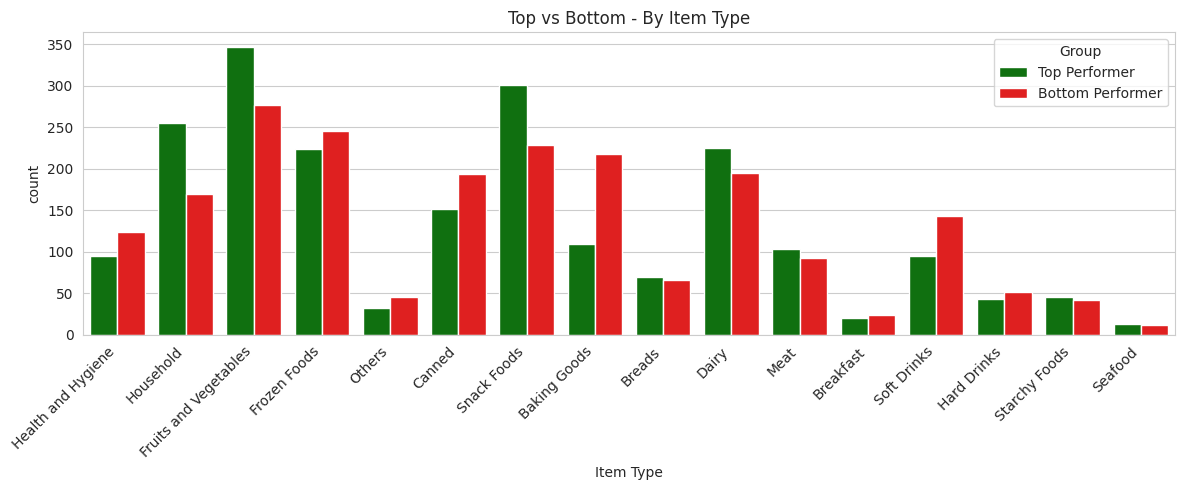

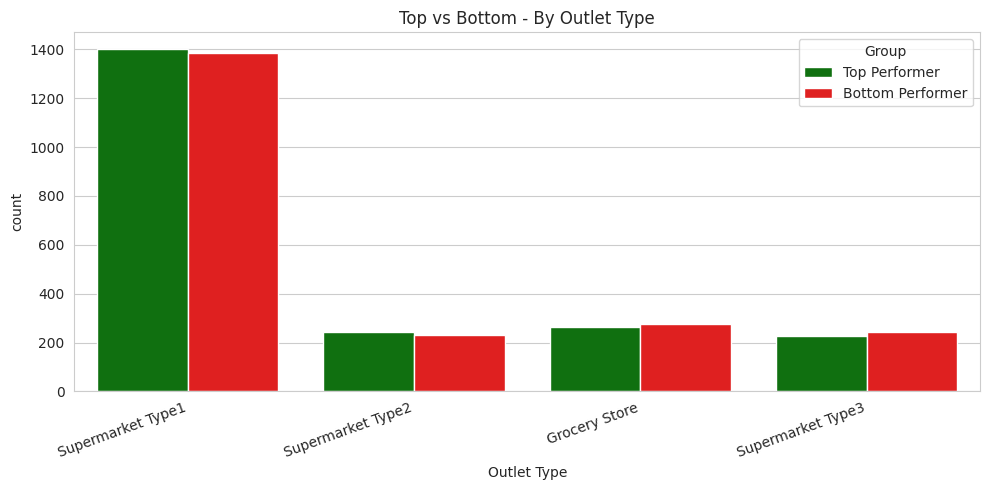

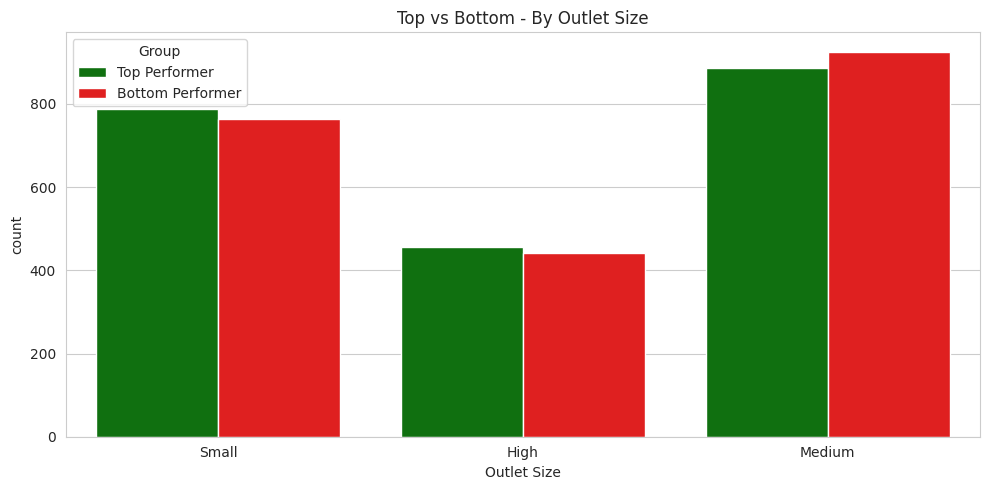

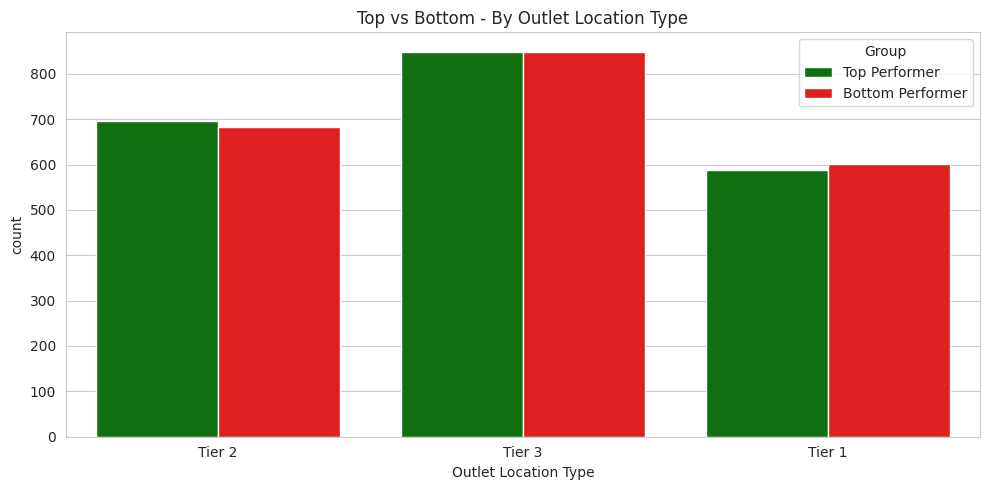

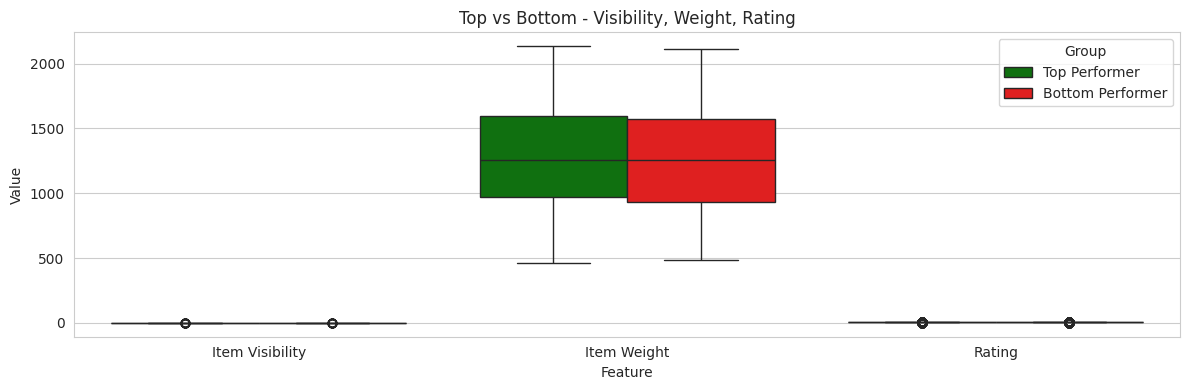

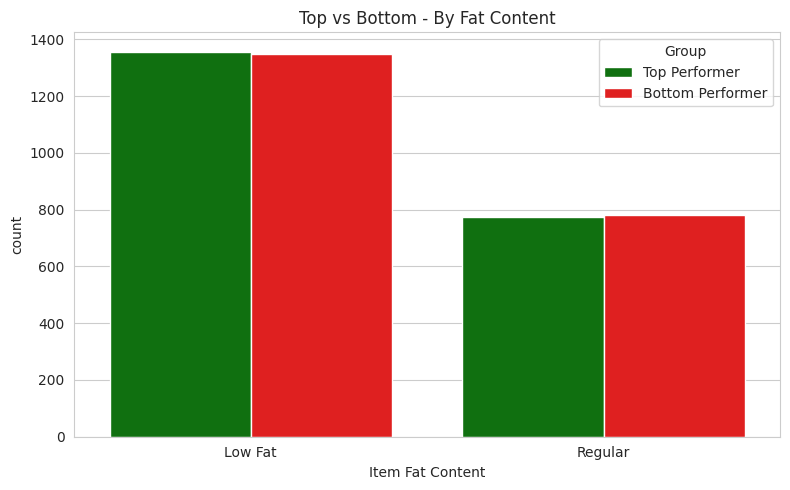

In [28]:
# Task 3.4: Top vs Bottom Performers - Wanted Visuals Only

# Split - Top 25% vs Bottom 25% by Sales
q75 = df["Sales"].quantile(0.75)
q25 = df["Sales"].quantile(0.25)
top = df[df["Sales"] >= q75].copy()
bottom = df[df["Sales"] <= q25].copy()
top["Group"] = "Top Performer"
bottom["Group"] = "Bottom Performer"
comp = pd.concat([top, bottom])

# Visual 1: Item Type - Top vs Bottom
plt.figure(figsize=(12, 5))
sn.countplot(data=comp, x="Item Type", hue="Group", palette=["green", "red"])
plt.title("Top vs Bottom - By Item Type")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Visual 2: Outlet Type - Top vs Bottom
plt.figure(figsize=(10, 5))
sn.countplot(data=comp, x="Outlet Type", hue="Group", palette=["green", "red"])
plt.title("Top vs Bottom - By Outlet Type")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

# Visual 3: Outlet Size + Location - Top vs Bottom
plt.figure(figsize=(10, 5))
sn.countplot(data=comp, x="Outlet Size", hue="Group", palette=["green", "red"])
plt.title("Top vs Bottom - By Outlet Size")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sn.countplot(data=comp, x="Outlet Location Type", hue="Group", palette=["green", "red"])
plt.title("Top vs Bottom - By Outlet Location Type")
plt.tight_layout()
plt.show()

# Visual 4: Numbers That Differ - Visibility, Weight, Rating
plt.figure(figsize=(12, 4))
comp_melt = comp.melt(id_vars="Group", value_vars=["Item Visibility", "Item Weight", "Rating"], var_name="Feature", value_name="Value")
sn.boxplot(data=comp_melt, x="Feature", y="Value", hue="Group", palette=["green", "red"])
plt.title("Top vs Bottom - Visibility, Weight, Rating")
plt.tight_layout()
plt.show()

# Visual 5: Fat Content - Top vs Bottom
plt.figure(figsize=(8, 5))
sn.countplot(data=comp, x="Item Fat Content", hue="Group", palette=["green", "red"])
plt.title("Top vs Bottom - By Fat Content")
plt.tight_layout()
plt.show()

# Got it - Consultancy view, point-wise:

*1. Item Type - Only Lever That Works*
- *What we see:* Top outlets win on fresh and daily-use categories. Bottom outlets are stuck with slow-moving pantry categories.
- *What it means:* Customer is not rejecting the outlet, they are rejecting the assortment.
- *What to do:* Rebalance shelf space to Top categories. Cut depth of Bottom categories, don't cut them fully.

*2. Outlet Type - No Advantage*
- *What we see:* Supermarket vs Grocery - performance is same.
- *What it means:* Format is not the problem. Copying another format will not fix sales.
- *What to do:* Stop format debate. Fix operations inside existing format.

*3. Outlet Size - Bigger Is Not Better*
- *What we see:* Medium outlets carry the bulk of underperformance.
- *What it means:* Scale is amplifying bad assortment, not solving it.
- *What to do:* Fix Medium first before any expansion. Expansion will only scale the loss.

*4. Location Type - Location Is Neutral*
- *What we see:* Tier 1, 2, 3 all behave same.
- *What it means:* Catchment is not the constraint.
- *What to do:* Don't invest in relocation. Invest in in-store execution.

*5. Visibility, Weight, Rating - No Return*
- *What we see:* Top and Bottom look identical on these.
- *What it means:* These are hygiene factors, not growth drivers.
- *What to do:* Maintain minimum standard. Move budget away from here.

*6. Fat Content - No Preference Shift*
- *What we see:* Low Fat and Regular both sell same in Top and Bottom.
- *What it means:* Health positioning is not driving the gap.
- *What to do:* Keep current mix. Don't reposition on Fat Content.

*Consultancy Conclusion:* Don't spend on outlet, location, size, visibility, or fat content. One fix only: *Assortment correction in Medium outlets, led by Item Type.*

# Task 4.1: Identify the products that are contributing more to sales.

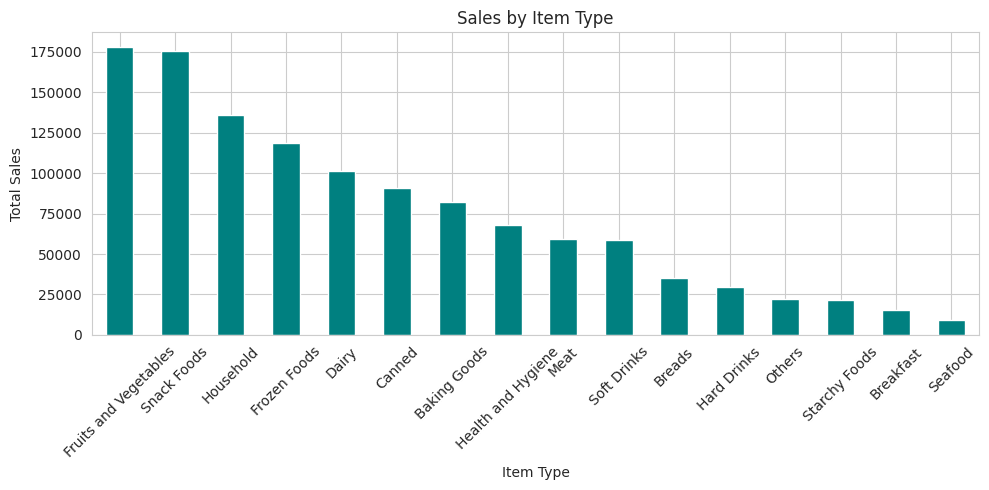

Item Type
Fruits and Vegetables    178124.0810
Snack Foods              175433.9224
Household                135976.5254
Frozen Foods             118558.8814
Dairy                    101276.4616
Canned                    90706.7290
Baking Goods              81894.7364
Health and Hygiene        68025.8388
Meat                      59449.8638
Soft Drinks               58514.1670
Breads                    35379.1198
Hard Drinks               29334.6806
Others                    22451.8916
Starchy Foods             21880.0274
Breakfast                 15596.6966
Seafood                    9077.8700
Name: Sales, dtype: float64


In [29]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Sales by Item Type - Which category contributes more
sales_by_type = df.groupby("Item Type")["Sales"].sum().sort_values(ascending=False)

plt.figure(figsize=(10,5))
sales_by_type.plot(kind="bar", color="teal")
plt.title("Sales by Item Type")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(sales_by_type)



# ask 4.2: Identify the outlets and locations that are performing better.

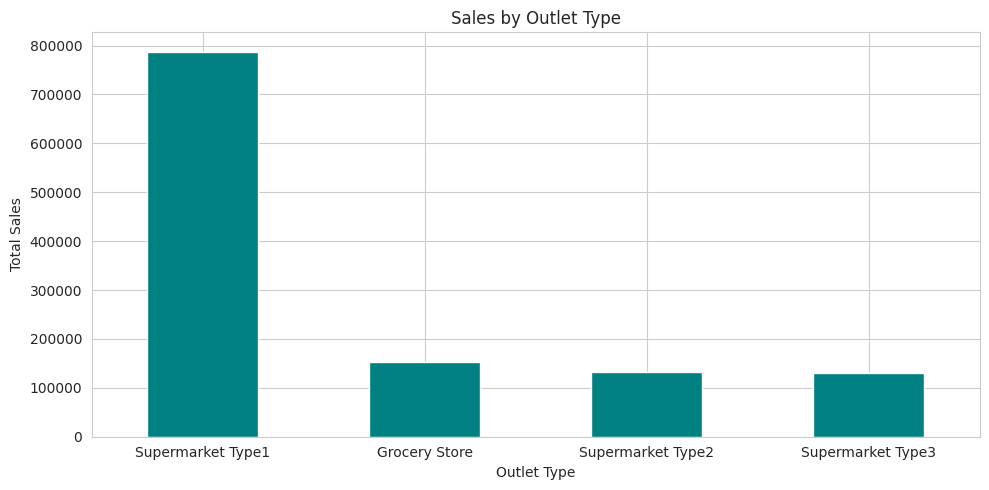

Outlet Type
Supermarket Type1    787549.8928
Grocery Store        151939.1490
Supermarket Type2    131477.7764
Supermarket Type3    130714.6746
Name: Sales, dtype: float64


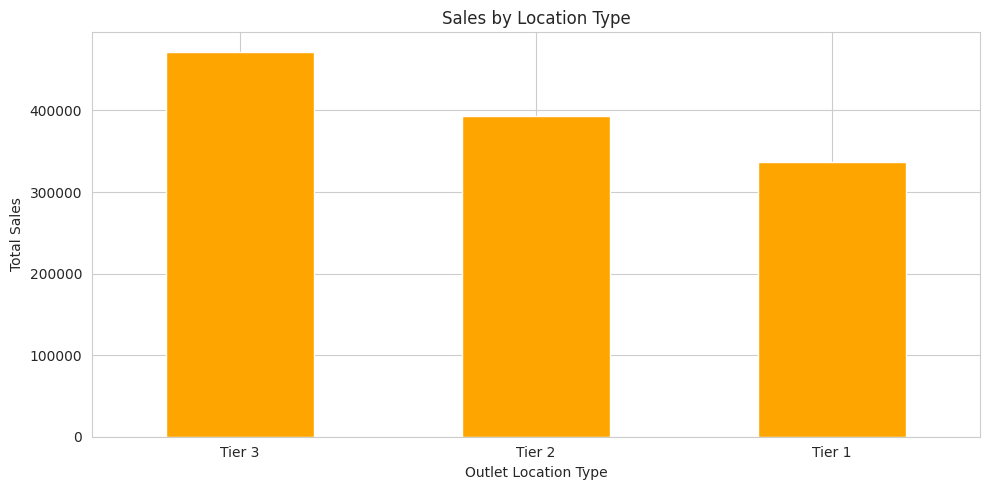

Outlet Location Type
Tier 3    472133.0332
Tier 2    393150.6476
Tier 1    336397.8120
Name: Sales, dtype: float64


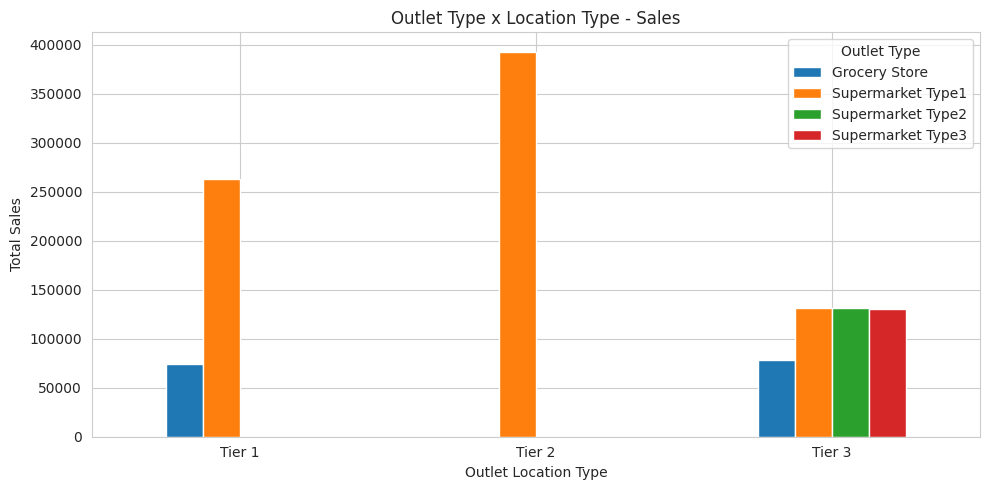

Outlet Type           Grocery Store  Supermarket Type1  Supermarket Type2  \
Outlet Location Type                                                        
Tier 1                   73807.5824        262590.2296                NaN   
Tier 2                          NaN        393150.6476                NaN   
Tier 3                   78131.5666        131809.0156        131477.7764   

Outlet Type           Supermarket Type3  
Outlet Location Type                     
Tier 1                              NaN  
Tier 2                              NaN  
Tier 3                      130714.6746  


In [30]:
import matplotlib.pyplot as plt

# 1. Sales by Outlet Type
sales_by_type = df.groupby("Outlet Type")["Sales"].sum().sort_values(ascending=False)

plt.figure(figsize=(10,5))
sales_by_type.plot(kind="bar", color="teal")
plt.title("Sales by Outlet Type")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
print(sales_by_type)

# 2. Sales by Location Type
sales_by_loc = df.groupby("Outlet Location Type")["Sales"].sum().sort_values(ascending=False)

plt.figure(figsize=(10,5))
sales_by_loc.plot(kind="bar", color="orange")
plt.title("Sales by Location Type")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
print(sales_by_loc)

# 3. Combined - Outlet Type x Location Type (most important for 4.2)
sales_combo = df.groupby(["Outlet Location Type", "Outlet Type"])["Sales"].sum().unstack()

sales_combo.plot(kind="bar", figsize=(10,5))
plt.title("Outlet Type x Location Type - Sales")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
print(sales_combo)

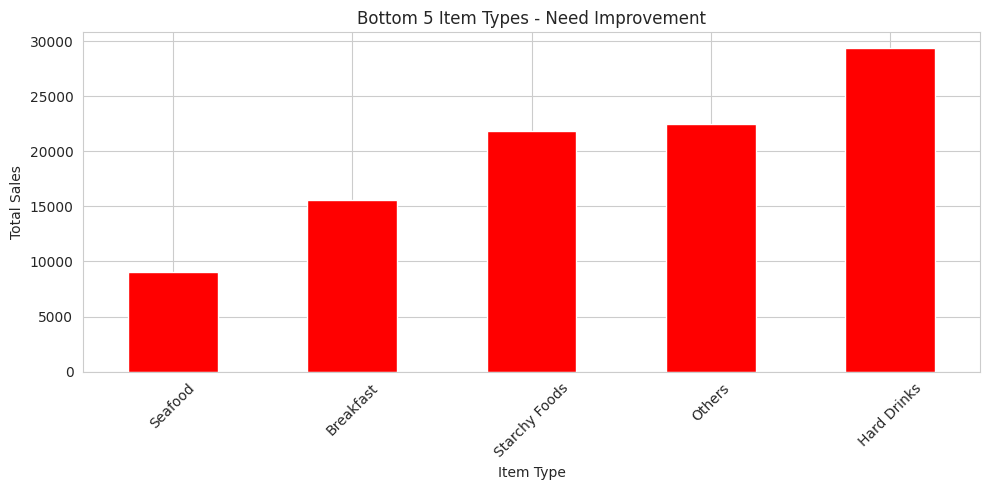

Item Type
Seafood           9077.8700
Breakfast        15596.6966
Starchy Foods    21880.0274
Others           22451.8916
Hard Drinks      29334.6806
Name: Sales, dtype: float64


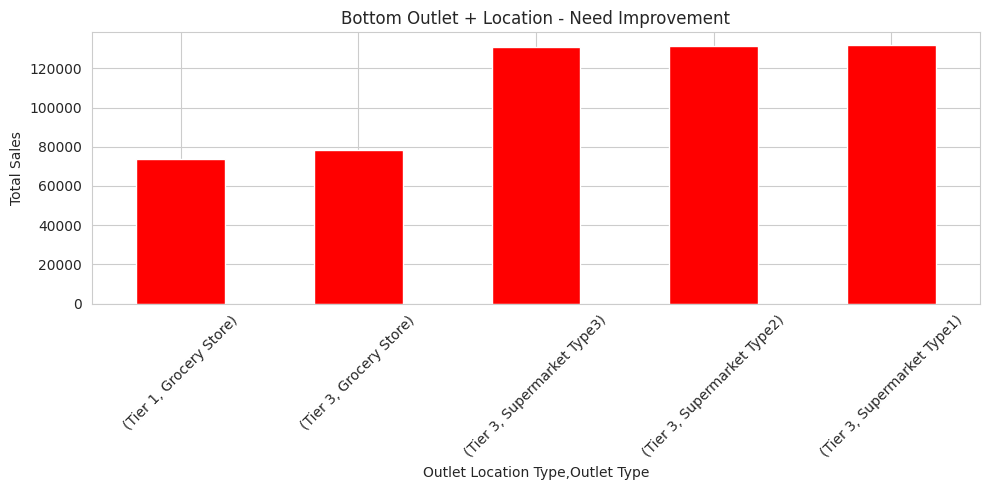

Outlet Location Type  Outlet Type      
Tier 1                Grocery Store         73807.5824
Tier 3                Grocery Store         78131.5666
                      Supermarket Type3    130714.6746
                      Supermarket Type2    131477.7764
                      Supermarket Type1    131809.0156
Name: Sales, dtype: float64


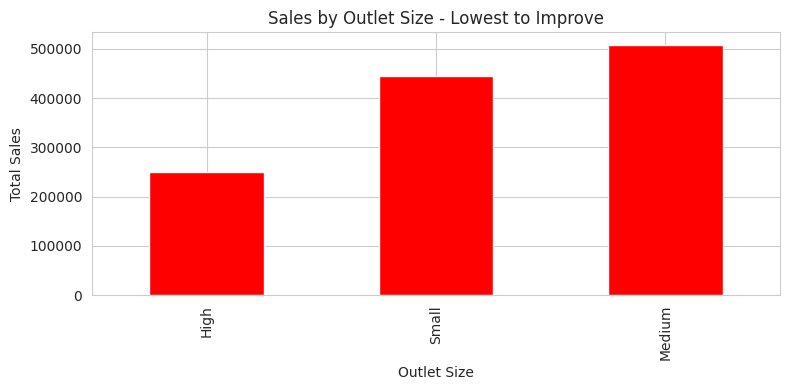

Outlet Size
High      248991.5860
Small     444794.1704
Medium    507895.7364
Name: Sales, dtype: float64


In [31]:
import matplotlib.pyplot as plt

# 1. Bottom Item Types - Products to improve
bottom_item = df.groupby("Item Type")["Sales"].sum().sort_values().head(5)

plt.figure(figsize=(10,5))
bottom_item.plot(kind="bar", color="red")
plt.title("Bottom 5 Item Types - Need Improvement")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
print(bottom_item)

# 2. Bottom Outlet Type x Location - Outlets to improve
bottom_combo = df.groupby(["Outlet Location Type", "Outlet Type"])["Sales"].sum().sort_values().head(5)

plt.figure(figsize=(10,5))
bottom_combo.plot(kind="bar", color="red")
plt.title("Bottom Outlet + Location - Need Improvement")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
print(bottom_combo)

# 3. Bottom Outlet Size - Area to improve
bottom_size = df.groupby("Outlet Size")["Sales"].sum().sort_values()

bottom_size.plot(kind="bar", color="red", figsize=(8,4))
plt.title("Sales by Outlet Size - Lowest to Improve")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()
print(bottom_size)

**Task 4.3: Identify products, outlets, and areas where performance can be improved**

**Products**
- The lowest total sales are Seafood (9,077.87), Breakfast (15,596.70), Starchy Foods (21,880.03), Others (22,451.89) and Hard Drinks (29,334.68). Each has only 64 to 214 records, so these categories are small. Their average per record is normal.
- Baking Goods has the lowest average sales per record (126.38). Baking Goods, Canned, Soft Drinks, Frozen Foods and Health and Hygiene have more bottom-25% records than top-25% records.

**Outlets**
- Grocery Stores in Tier 1 (73,807.58) and Tier 3 (78,131.57) are the lowest outlet and tier combinations.

**Areas**
- Tier 1 has the lowest total (336,397.81). High-size outlets have the lowest total (248,991.59) but the highest average (142.04). Both gaps come from having fewer records, not from weaker sales per record.

**Task 4.4: Practical suggestions to improve sales and overall business performance**
1. Keep stock and range strong in Fruits and Vegetables, Snack Foods, Household and Dairy. They have the highest totals and more top-25% than bottom-25% records.
2. Review the slow lines in Baking Goods, Canned, Soft Drinks, Frozen Foods and Health and Hygiene before removing any.
3. Test a wider range of Seafood, Breakfast, Starchy Foods and Hard Drinks in a few outlets. Their averages are normal but their listings are few.
4. Review Grocery Stores in Tier 1 and Tier 3 using outlet-level data.
5. Judge outlets on average sales per record, not total sales alone. Supermarket Type 1 has 65.4% of the records and 65.5% of the sales.
6. Run a small pilot before changing item visibility. Its correlation with sales is −0.001. Also confirm the visibility values above about 18 with the data owner.
7. Fix data capture: make weight mandatory (17.2% was missing), use fixed fat-content labels, and record units. Add date, units sold and cost so trends and profitability can be studied later.

Sales alone do not show profit, so these suggestions are about range, outlet review and data, not profitability.

## Full Business Analytics Report

This notebook contains the Python analysis for the BlinkIT Grocery Sales Analysis project. The complete findings, charts, business interpretation and recommendations (Tasks 4.3 and 4.4) are written up in the report below.

**Please read the full report for the final results:**
- BlinkIT_Grocery_Sales_Report_SapphireIQ.pdf

The report covers the dataset overview, data cleaning, sales analysis by product, outlet and location, relationships with sales, improvement areas, practical suggestions, and limitations.